<a href="https://colab.research.google.com/github/ramya072006/Deep-Learning/blob/main/UNIT%205%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense
from tensorflow.keras.models import Model


english = [
    "hello", "how are you", "good morning", "thank you",
    "good night", "i am happy", "what is your name",
    "welcome", "see you", "good afternoon"
]

french = [
    "bonjour", "comment allez vous", "bonjour",
    "merci", "bonne nuit", "je suis heureux",
    "quel est votre nom", "bienvenue",
    "a bientot", "bon apres midi"
]


french = ["<start> " + s + " <end>" for s in french]

eng_tok = Tokenizer(filters='')
fr_tok = Tokenizer(filters='')

eng_tok.fit_on_texts(english)
fr_tok.fit_on_texts(french)

X = pad_sequences(eng_tok.texts_to_sequences(english), padding='post')
Y = pad_sequences(fr_tok.texts_to_sequences(french), padding='post')

decoder_input = Y[:, :-1]
decoder_output = Y[:, 1:]

eng_vocab = len(eng_tok.word_index) + 1
fr_vocab = len(fr_tok.word_index) + 1

# Encoder
encoder_input = Input(shape=(X.shape[1],))
enc_emb = Embedding(eng_vocab, 64)(encoder_input)
_, h, c = LSTM(128, return_state=True)(enc_emb)

# Decoder
decoder_input_layer = Input(shape=(None,))
dec_emb_layer = Embedding(fr_vocab, 64)
dec_emb = dec_emb_layer(decoder_input_layer)

decoder_lstm = LSTM(128, return_sequences=True, return_state=True)
dec_output, _, _ = decoder_lstm(dec_emb, initial_state=[h, c])

output_layer = Dense(fr_vocab, activation='softmax')
output = output_layer(dec_output)

model = Model([encoder_input, decoder_input_layer], output)

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.fit(
    [X, decoder_input],
    decoder_output,
    epochs=150,
    batch_size=2,
    verbose=0
)

loss, accuracy = model.evaluate(
    [X, decoder_input], decoder_output, verbose=0
)

print("Translation Loss:", round(loss, 4))
print("Translation Accuracy:", round(accuracy * 100, 2), "%")

def translate(sentence):
    seq = eng_tok.texts_to_sequences([sentence])
    seq = pad_sequences(seq, maxlen=X.shape[1], padding='post')

    enc_model = Model(encoder_input, [h, c])
    state_h, state_c = enc_model.predict(seq, verbose=0)

    start_id = fr_tok.word_index['<start>']
    end_id = fr_tok.word_index['<end>']

    result = []
    token = np.array([[start_id]])

    for _ in range(15):
        embedding = dec_emb_layer(token)
        pred, state_h, state_c = decoder_lstm(
            embedding, initial_state=[state_h, state_c]
        )
        probabilities = output_layer(pred)
        next_id = int(np.argmax(probabilities[0, -1, :]))

        if next_id == end_id:
            break

        word = fr_tok.index_word.get(next_id, '')
        result.append(word)
        token = np.array([[next_id]])

    return " ".join(result)

print("English: hello")
print("French Translation:", translate("hello"))

Translation Loss: 0.0053
Translation Accuracy: 100.0 %
English: hello
French Translation: bonjour


In [2]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, Dense

np.random.seed(42)
tf.random.set_seed(42)


X = np.random.randint(0, 2, (3000, 50, 1)).astype('float32')

y = X[:, 0, 0]


rnn = Sequential([
    SimpleRNN(32, input_shape=(50, 1)),
    Dense(1, activation='sigmoid')
])

rnn.compile(optimizer='adam',
            loss='binary_crossentropy',
            metrics=['accuracy'])

rnn.fit(X, y, epochs=10, batch_size=32, verbose=0)

# LSTM model
lstm = Sequential([
    LSTM(32, input_shape=(50, 1)),
    Dense(1, activation='sigmoid')
])

lstm.compile(optimizer='adam',
             loss='binary_crossentropy',
             metrics=['accuracy'])

lstm.fit(X, y, epochs=10, batch_size=32, verbose=0)

# Evaluate models
rnn_loss, rnn_acc = rnn.evaluate(X, y, verbose=0)
lstm_loss, lstm_acc = lstm.evaluate(X, y, verbose=0)

print("RNN Accuracy:", round(rnn_acc * 100, 2), "%")
print("LSTM Accuracy:", round(lstm_acc * 100, 2), "%")

print("\nComparison:")
print("RNN Loss:", round(rnn_loss, 4))
print("LSTM Loss:", round(lstm_loss, 4))

if lstm_acc > rnn_acc:
    print("LSTM performs better on this experiment.")
else:
    print("RNN performs better on this experiment.")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


RNN Accuracy: 100.0 %
LSTM Accuracy: 51.77 %

Comparison:
RNN Loss: 0.001
LSTM Loss: 0.6924
RNN performs better on this experiment.


Original Dataset:
   Age  Blood_Pressure  Sugar_Level  Cholesterol  Heart_Rate        BMI
0   58             167          131          277          82  24.027145
1   71             176          120          165          68  22.720961
2   48             151          128          236          71  26.299700
3   34             129          187          125         112  18.857189
4   62             174          165          218          60  31.601585

Reduced Dataset:
[[ 0.74968038 -1.1218241 ]
 [-1.61160283 -1.30294645]
 [-0.06548476 -0.25146808]
 [-0.38346958  0.15681777]
 [-0.22817707  0.16556074]]

Explained Variance Ratio:
[0.22918408 0.19701045]
Total Variance Preserved: 42.62 %


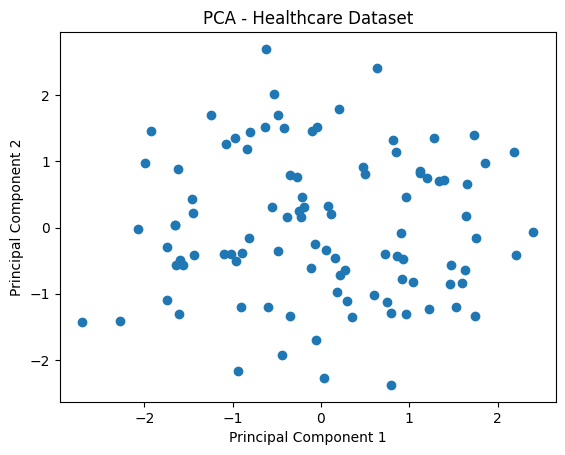

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

np.random.seed(42)

data = pd.DataFrame({
    'Age': np.random.randint(20, 80, 100),
    'Blood_Pressure': np.random.randint(90, 180, 100),
    'Sugar_Level': np.random.randint(70, 200, 100),
    'Cholesterol': np.random.randint(120, 280, 100),
    'Heart_Rate': np.random.randint(60, 120, 100),
    'BMI': np.random.uniform(18, 40, 100)
})

print("Original Dataset:")
print(data.head())

scaler = StandardScaler()
scaled_data = scaler.fit_transform(data)

pca = PCA(n_components=2)
transformed_data = pca.fit_transform(scaled_data)

print("\nReduced Dataset:")
print(transformed_data[:5])

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("Total Variance Preserved:",
      round(sum(pca.explained_variance_ratio_) * 100, 2), "%")


plt.scatter(transformed_data[:, 0],
            transformed_data[:, 1])

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - Healthcare Dataset")
plt.show()

Original Shape: (150, 4)
Reduced Shape: (150, 2)
Explained Variance: [0.72962445 0.22850762]

Original Accuracy: 93.33333333333333 %
PCA Accuracy: 86.66666666666667 %


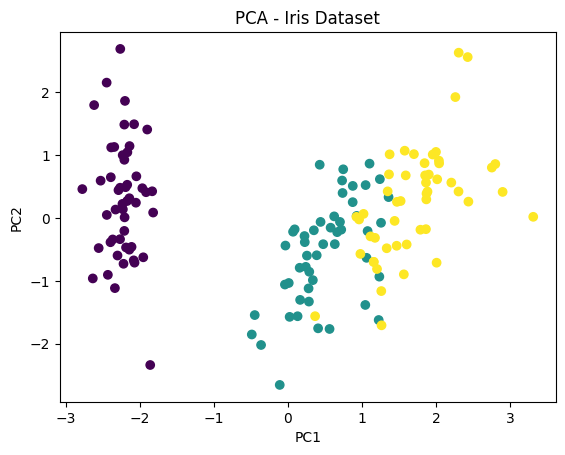

In [4]:
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

iris = load_iris()
X = iris.data
y = iris.target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Original Shape:", X.shape)
print("Reduced Shape:", X_pca.shape)

print("Explained Variance:",
      pca.explained_variance_ratio_)


X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42,
    stratify=y
)

model1 = RandomForestClassifier(random_state=42)
model1.fit(X_train, y_train)
pred1 = model1.predict(X_test)

Xp_train, Xp_test, yp_train, yp_test = train_test_split(
    X_pca, y, test_size=0.2, random_state=42,
    stratify=y
)

model2 = RandomForestClassifier(random_state=42)
model2.fit(Xp_train, yp_train)
pred2 = model2.predict(Xp_test)

print("\nOriginal Accuracy:",
      accuracy_score(y_test, pred1) * 100, "%")

print("PCA Accuracy:",
      accuracy_score(yp_test, pred2) * 100, "%")

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis')
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA - Iris Dataset")
plt.show()

Original Dimensions: (300, 5)
Reduced Dimensions: (300, 2)
Explained Variance: [0.50542641 0.40618154]


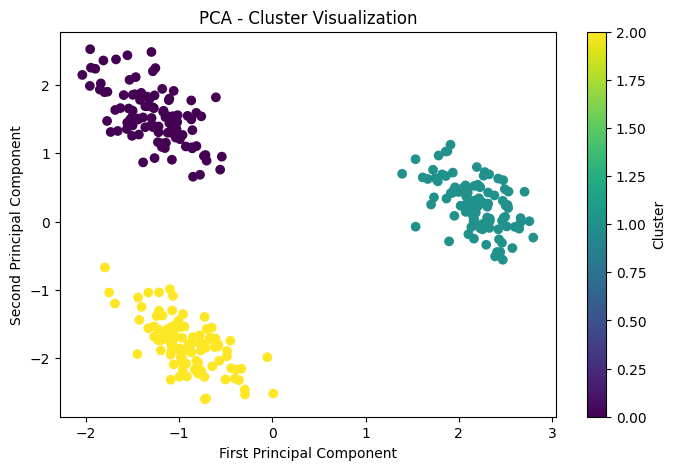

In [5]:
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


X, y = make_blobs(
    n_samples=300,
    centers=3,
    n_features=5,
    random_state=42
)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


pca = PCA(n_components=2)
X_reduced = pca.fit_transform(X_scaled)

print("Original Dimensions:", X.shape)
print("Reduced Dimensions:", X_reduced.shape)

print("Explained Variance:",
      pca.explained_variance_ratio_)

plt.figure(figsize=(8, 5))

plt.scatter(
    X_reduced[:, 0],
    X_reduced[:, 1],
    c=y,
    cmap='viridis'
)

plt.xlabel("First Principal Component")
plt.ylabel("Second Principal Component")
plt.title("PCA - Cluster Visualization")
plt.colorbar(label="Cluster")
plt.show()

In [6]:
import numpy as np

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report


X, y = make_classification(
    n_samples=1000,
    n_features=20,
    n_informative=10,
    n_redundant=5,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


model1 = RandomForestClassifier(random_state=42)
model1.fit(X_train_scaled, y_train)

pred1 = model1.predict(X_test_scaled)
acc1 = accuracy_score(y_test, pred1)

pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

model2 = RandomForestClassifier(random_state=42)
model2.fit(X_train_pca, y_train)

pred2 = model2.predict(X_test_pca)
acc2 = accuracy_score(y_test, pred2)

print("Original Features:", X.shape[1])
print("PCA Features:", X_train_pca.shape[1])

print("\nAccuracy Before PCA:", round(acc1 * 100, 2), "%")
print("Accuracy After PCA:", round(acc2 * 100, 2), "%")

print("\nClassification Report After PCA:")
print(classification_report(y_test, pred2))

if acc2 > acc1:
    print("PCA improved classification performance.")
elif acc2 < acc1:
    print("PCA reduced classification performance.")
else:
    print("Both methods achieved equal accuracy.")

Original Features: 20
PCA Features: 13

Accuracy Before PCA: 91.0 %
Accuracy After PCA: 81.5 %

Classification Report After PCA:
              precision    recall  f1-score   support

           0       0.84      0.78      0.81        99
           1       0.80      0.85      0.82       101

    accuracy                           0.81       200
   macro avg       0.82      0.81      0.81       200
weighted avg       0.82      0.81      0.81       200

PCA reduced classification performance.


Original Features: 30

Individual Explained Variance:
[4.42720256e-01 1.89711820e-01 9.39316326e-02 6.60213492e-02
 5.49576849e-02 4.02452204e-02 2.25073371e-02 1.58872380e-02
 1.38964937e-02 1.16897819e-02 9.79718988e-03 8.70537901e-03
 8.04524987e-03 5.23365745e-03 3.13783217e-03 2.66209337e-03
 1.97996793e-03 1.75395945e-03 1.64925306e-03 1.03864675e-03
 9.99096464e-04 9.14646751e-04 8.11361259e-04 6.01833567e-04
 5.16042379e-04 2.72587995e-04 2.30015463e-04 5.29779290e-05
 2.49601032e-05 4.43482743e-06]

Cumulative Explained Variance:
[0.44272026 0.63243208 0.72636371 0.79238506 0.84734274 0.88758796
 0.9100953  0.92598254 0.93987903 0.95156881 0.961366   0.97007138
 0.97811663 0.98335029 0.98648812 0.98915022 0.99113018 0.99288414
 0.9945334  0.99557204 0.99657114 0.99748579 0.99829715 0.99889898
 0.99941502 0.99968761 0.99991763 0.99997061 0.99999557 1.        ]

Components required for 95% variance: 10
Variance Retained: 95.16 %


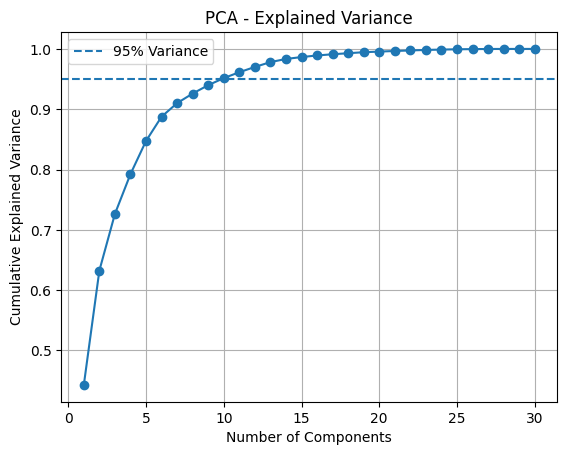

In [7]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


data = load_breast_cancer()
X = data.data

print("Original Features:", X.shape[1])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


pca = PCA()
X_pca = pca.fit_transform(X_scaled)


variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(variance)

components = np.argmax(cumulative_variance >= 0.95) + 1

print("\nIndividual Explained Variance:")
print(variance)

print("\nCumulative Explained Variance:")
print(cumulative_variance)

print("\nComponents required for 95% variance:",
      components)

print("Variance Retained:",
      round(cumulative_variance[components - 1] * 100, 2),
      "%")

# Plot
plt.plot(range(1, len(cumulative_variance) + 1),
         cumulative_variance, marker='o')

plt.axhline(y=0.95, linestyle='--', label='95% Variance')
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Explained Variance")
plt.legend()
plt.grid()
plt.show()

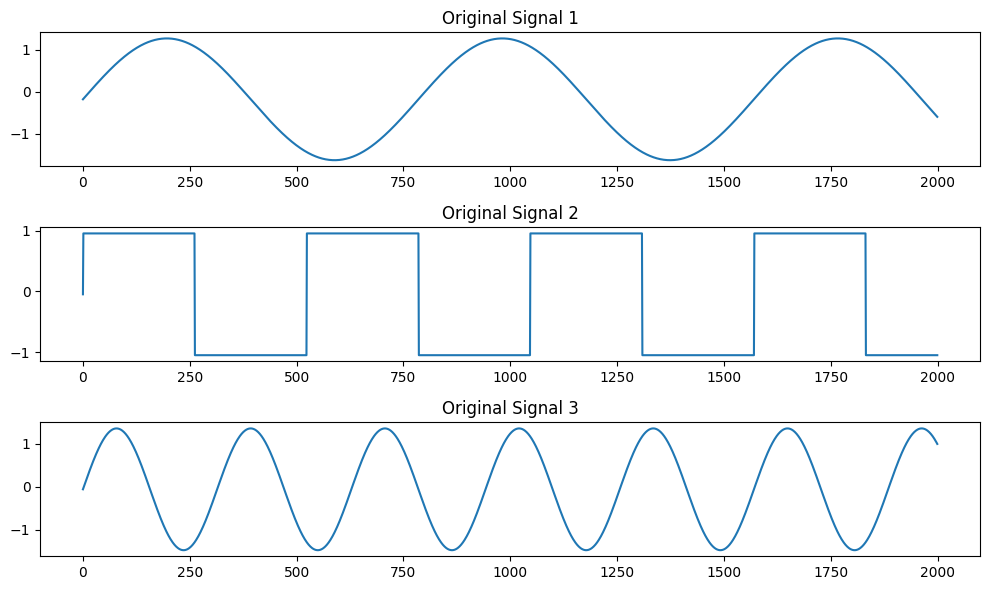

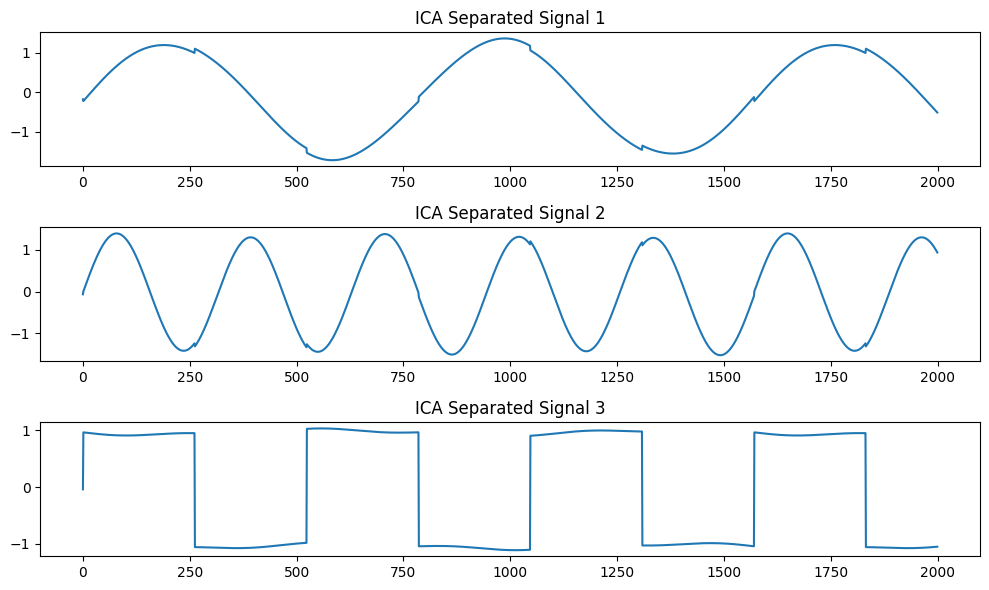

Original Signal Shape: (2000, 3)
Mixed Signal Shape: (2000, 3)
Separated Signal Shape: (2000, 3)
ICA Separation Completed Successfully


In [8]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import FastICA


np.random.seed(42)

time = np.linspace(0, 8, 2000)

s1 = np.sin(2 * time)
s2 = np.sign(np.sin(3 * time))
s3 = np.sin(5 * time)

S = np.c_[s1, s2, s3]


S = (S - S.mean(axis=0)) / S.std(axis=0)

A = np.array([
    [1, 1, 0.5],
    [0.5, 2, 1],
    [1.5, 0.5, 2]
])

mixed = S @ A.T

ica = FastICA(
    n_components=3,
    random_state=42,
    max_iter=1000,
    whiten='unit-variance'
)

separated = ica.fit_transform(mixed)


plt.figure(figsize=(10, 6))

for i in range(3):
    plt.subplot(3, 1, i + 1)
    plt.plot(S[:, i])
    plt.title("Original Signal " + str(i + 1))

plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 6))

for i in range(3):
    plt.subplot(3, 1, i + 1)
    plt.plot(separated[:, i])
    plt.title("ICA Separated Signal " + str(i + 1))

plt.tight_layout()
plt.show()

print("Original Signal Shape:", S.shape)
print("Mixed Signal Shape:", mixed.shape)
print("Separated Signal Shape:", separated.shape)
print("ICA Separation Completed Successfully")

Source 1 Correlations: -0.106 0.994
Source 2 Correlations: 0.994 0.106
Total Best Matching Correlation: 1.989


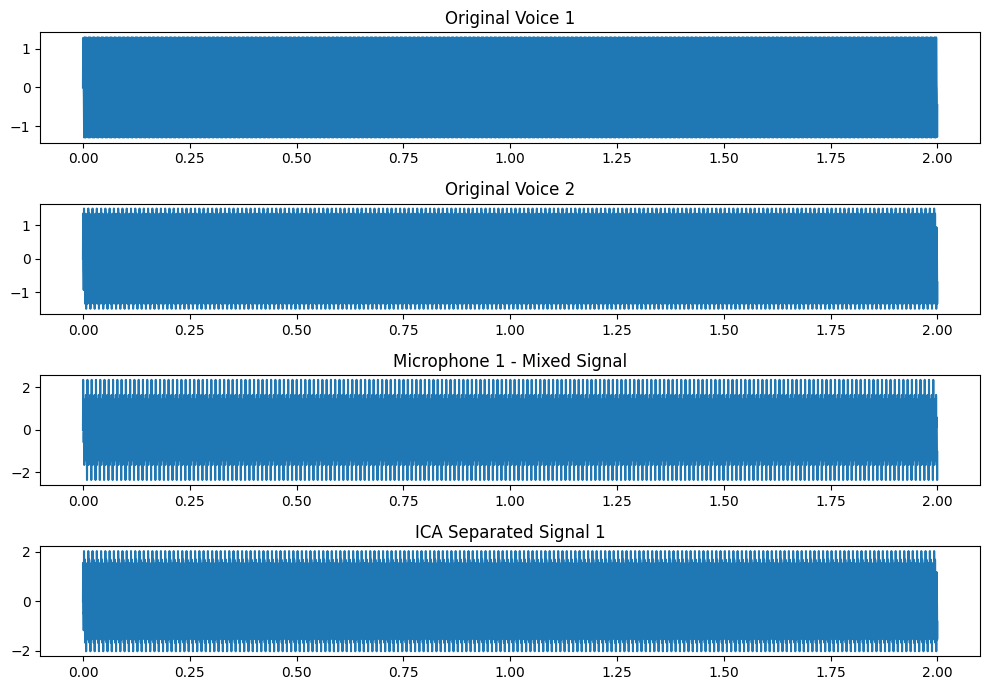

Blind Source Separation Completed


In [9]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import FastICA


np.random.seed(42)

fs = 8000
t = np.arange(0, 2, 1/fs)


voice1 = np.sin(2 * np.pi * 300 * t)
voice1 += 0.5 * np.sin(2 * np.pi * 600 * t)

voice2 = np.sin(2 * np.pi * 500 * t)
voice2 += 0.5 * np.sin(2 * np.pi * 900 * t)

S = np.c_[voice1, voice2]

S = (S - S.mean(axis=0)) / S.std(axis=0)


A = np.array([
    [1, 0.5],
    [0.5, 1]
])

mixed = S @ A.T


ica = FastICA(
    n_components=2,
    random_state=42,
    max_iter=1000,
    whiten='unit-variance'
)

separated = ica.fit_transform(mixed)

corr1 = np.corrcoef(S[:, 0], separated[:, 0])[0, 1]
corr2 = np.corrcoef(S[:, 0], separated[:, 1])[0, 1]

corr3 = np.corrcoef(S[:, 1], separated[:, 0])[0, 1]
corr4 = np.corrcoef(S[:, 1], separated[:, 1])[0, 1]

best_match = max(
    abs(corr1) + abs(corr4),
    abs(corr2) + abs(corr3)
)

print("Source 1 Correlations:", round(corr1, 3), round(corr2, 3))
print("Source 2 Correlations:", round(corr3, 3), round(corr4, 3))
print("Total Best Matching Correlation:", round(best_match, 3))


plt.figure(figsize=(10, 7))

plt.subplot(4, 1, 1)
plt.plot(t, voice1)
plt.title("Original Voice 1")

plt.subplot(4, 1, 2)
plt.plot(t, voice2)
plt.title("Original Voice 2")

plt.subplot(4, 1, 3)
plt.plot(t, mixed[:, 0])
plt.title("Microphone 1 - Mixed Signal")

plt.subplot(4, 1, 4)
plt.plot(t, separated[:, 0])
plt.title("ICA Separated Signal 1")

plt.tight_layout()
plt.show()

print("Blind Source Separation Completed")

PCA Explained Variance:
[0.96402631 0.02716266 0.00881103]

ICA Component Kurtosis:
[ 1.694  2.133 -1.216]

PCA Components Shape: (1000, 3)
ICA Components Shape: (1000, 3)


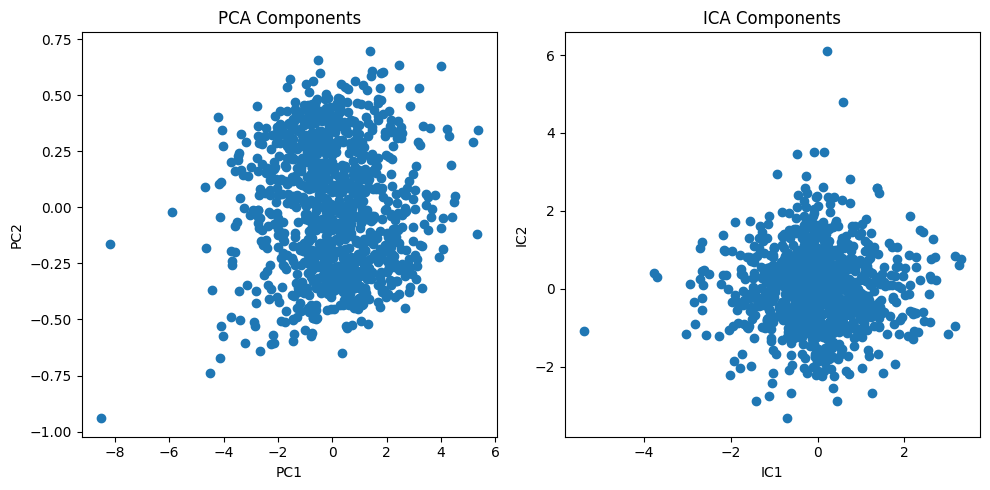


PCA and ICA Comparison Completed


In [10]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA, FastICA
from sklearn.preprocessing import StandardScaler

np.random.seed(42)

n = 1000

s1 = np.random.laplace(size=n)
s2 = np.random.uniform(-1, 1, n)
s3 = np.random.logistic(size=n)

S = np.c_[s1, s2, s3]


A = np.array([
    [1, 2, 1],
    [2, 1, 3],
    [1, 3, 2]
])

X = S @ A.T

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

ica = FastICA(
    n_components=3,
    random_state=42,
    max_iter=1000,
    whiten='unit-variance'
)

X_ica = ica.fit_transform(X_scaled)

print("PCA Explained Variance:")
print(pca.explained_variance_ratio_)

print("\nICA Component Kurtosis:")
print(np.round(
    np.array([
        np.mean((X_ica[:, i] - X_ica[:, i].mean())**4) /
        (np.var(X_ica[:, i])**2) - 3
        for i in range(3)
    ]), 3
))

print("\nPCA Components Shape:", X_pca.shape)
print("ICA Components Shape:", X_ica.shape)


plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_pca[:, 0], X_pca[:, 1])
plt.title("PCA Components")
plt.xlabel("PC1")
plt.ylabel("PC2")

plt.subplot(1, 2, 2)
plt.scatter(X_ica[:, 0], X_ica[:, 1])
plt.title("ICA Components")
plt.xlabel("IC1")
plt.ylabel("IC2")

plt.tight_layout()
plt.show()

print("\nPCA and ICA Comparison Completed")

Student Dataset:
       Marks  Attendance  Assignments  Participation  Study_Hours
0  49.938336   62.001289    50.866868      45.076441    74.967142
1  43.708969   61.048660    62.807500      30.213382    68.617357
2  52.090235   60.379511    70.062924      45.872650    76.476885
3  52.949873   56.641930    70.563767      51.477083    85.230299
4  44.270670   46.347431    64.599214      42.221032    67.658466

Factor Loadings:
               Factor 1  Factor 2
Marks             0.888     0.014
Attendance       -0.056    -0.068
Assignments       0.523     0.631
Participation     0.214     0.104
Study_Hours       0.524    -0.646

Factor Scores:
[[-0.13477122 -1.15244969]
 [-0.71909084 -0.27953678]
 [ 0.51451801 -0.36646543]
 [ 0.87818007 -0.86282449]
 [-0.59353302 -0.062098  ]]


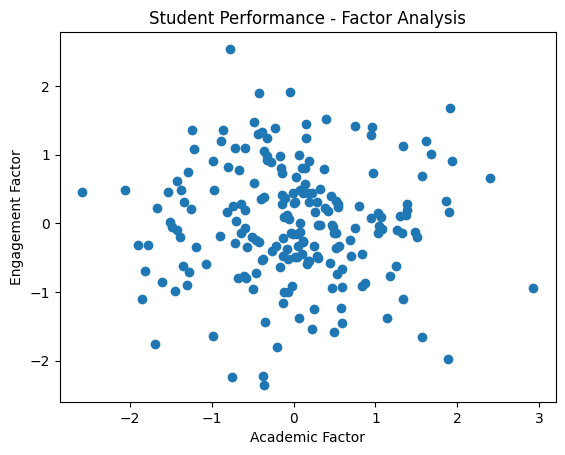

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import FactorAnalysis
from sklearn.preprocessing import StandardScaler

np.random.seed(42)

n = 200

study = np.random.normal(70, 10, n)
attendance = np.random.normal(75, 10, n)
assignment = np.random.normal(70, 12, n)
participation = np.random.normal(65, 12, n)

marks = 0.4 * study + 0.3 * assignment + np.random.normal(0, 5, n)
attendance_score = 0.7 * attendance + np.random.normal(0, 5, n)
participation_score = 0.6 * participation + np.random.normal(0, 5, n)

data = pd.DataFrame({
    'Marks': marks,
    'Attendance': attendance_score,
    'Assignments': assignment,
    'Participation': participation_score,
    'Study_Hours': study
})

print("Student Dataset:")
print(data.head())


scaler = StandardScaler()
X = scaler.fit_transform(data)

fa = FactorAnalysis(n_components=2, random_state=42)
factors = fa.fit_transform(X)

print("\nFactor Loadings:")
loadings = pd.DataFrame(
    fa.components_.T,
    index=data.columns,
    columns=['Factor 1', 'Factor 2']
)

print(loadings.round(3))

print("\nFactor Scores:")
print(factors[:5])


plt.scatter(factors[:, 0], factors[:, 1])
plt.xlabel("Academic Factor")
plt.ylabel("Engagement Factor")
plt.title("Student Performance - Factor Analysis")
plt.show()

Customer Dataset:
      Spending  Purchase_Frequency  Online_Activity  Discount_Usage  \
0  5496.714153           11.073362        26.083585       37.569886   
1  4861.735699           11.682354        41.009375       20.778347   
2  5647.688538           13.249154        50.078655       38.696059   
3  6523.029856           13.161406        50.704709       43.556379   
4  4765.846625            5.866992        43.249018       34.134349   

   Loyalty_Score  
0      81.259406  
1      63.807463  
2      71.153449  
3      64.452697  
4      64.786045  

Factor Loadings:
                    Factor 1  Factor 2
Spending               0.500     0.320
Purchase_Frequency     0.270    -0.139
Online_Activity       -0.254     0.029
Discount_Usage        -0.187     0.471
Loyalty_Score         -0.239     0.281

Transformed Customer Factors:
[[ 0.31619699  0.59655782]
 [ 0.37713458 -0.59993475]
 [ 0.38959057  0.46913618]
 [ 0.84150434  0.83851503]
 [-0.2660577   0.11026207]]


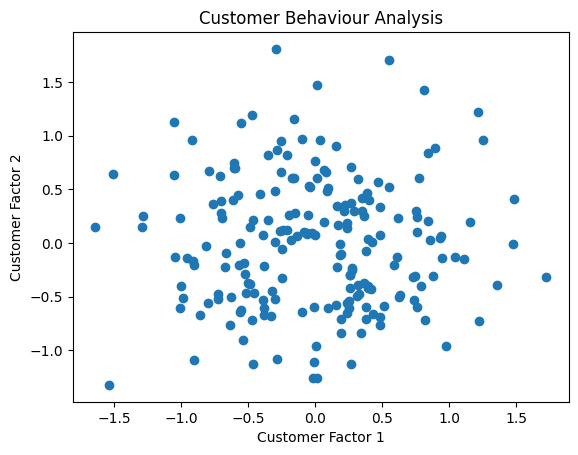

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import FactorAnalysis
from sklearn.preprocessing import StandardScaler

# Generate customer behaviour dataset
np.random.seed(42)

n = 200

spending = np.random.normal(5000, 1000, n)
frequency = np.random.normal(10, 3, n)
online = np.random.normal(50, 15, n)
discount = np.random.normal(30, 10, n)
loyalty = np.random.normal(70, 12, n)

data = pd.DataFrame({
    'Spending': spending,
    'Purchase_Frequency': frequency,
    'Online_Activity': online,
    'Discount_Usage': discount,
    'Loyalty_Score': loyalty
})

print("Customer Dataset:")
print(data.head())


scaler = StandardScaler()
X = scaler.fit_transform(data)


fa = FactorAnalysis(n_components=2, random_state=42)
X_factors = fa.fit_transform(X)


loadings = pd.DataFrame(
    fa.components_.T,
    index=data.columns,
    columns=['Factor 1', 'Factor 2']
)

print("\nFactor Loadings:")
print(loadings.round(3))

print("\nTransformed Customer Factors:")
print(X_factors[:5])

# Plot
plt.scatter(X_factors[:, 0], X_factors[:, 1])
plt.xlabel("Customer Factor 1")
plt.ylabel("Customer Factor 2")
plt.title("Customer Behaviour Analysis")
plt.show()

In [13]:
import numpy as np

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, FactorAnalysis
from sklearn.metrics import mean_squared_error


iris = load_iris()
X = iris.data


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
pca_reconstructed = pca.inverse_transform(X_pca)


fa = FactorAnalysis(n_components=2, random_state=42)
X_fa = fa.fit_transform(X_scaled)
fa_reconstructed = np.dot(X_fa, fa.components_) + fa.mean_


pca_error = mean_squared_error(
    X_scaled, pca_reconstructed
)

fa_error = mean_squared_error(
    X_scaled, fa_reconstructed
)

print("Original Features:", X.shape[1])
print("Reduced Features:", X_pca.shape[1])

print("\nPCA Reconstruction Error:",
      round(pca_error, 4))

print("Factor Analysis Reconstruction Error:",
      round(fa_error, 4))

print("\nComparison:")

if pca_error < fa_error:
    print("PCA has lower reconstruction error.")
elif fa_error < pca_error:
    print("Factor Analysis has lower reconstruction error.")
else:
    print("Both methods have equal reconstruction error.")

print("\nPCA Explained Variance:",
      pca.explained_variance_ratio_)

Original Features: 4
Reduced Features: 2

PCA Reconstruction Error: 0.0419
Factor Analysis Reconstruction Error: 0.1404

Comparison:
PCA has lower reconstruction error.

PCA Explained Variance: [0.72962445 0.22850762]


Generated Data Shape: (1000, 3)

Original Mean:
[5, 10, 15]

Estimated Mean:
[ 4.96204224 10.06715577 15.10659225]

Original Covariance:
[[2.  0.5 0.3]
 [0.5 3.  0.6]
 [0.3 0.6 4. ]]

Estimated Covariance:
[[1.8924984  0.43239916 0.30277352]
 [0.43239916 2.87984825 0.36954091]
 [0.30277352 0.36954091 3.95211642]]


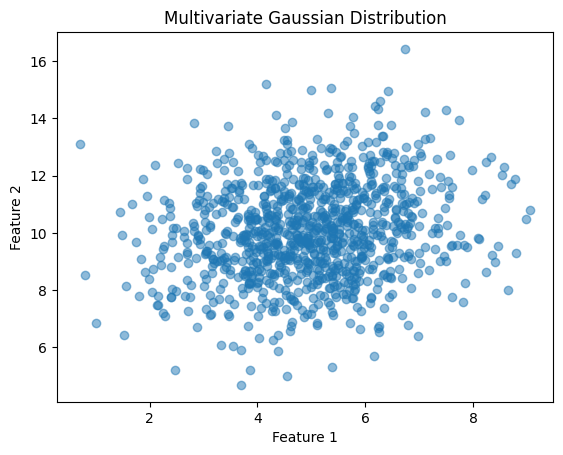


Statistical Evaluation:
Feature Means: [ 4.96204224 10.06715577 15.10659225]
Feature Variances: [1.8924984  2.87984825 3.95211642]

Gaussian Data Generation Completed


In [14]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import multivariate_normal

np.random.seed(42)

mean = [5, 10, 15]

covariance = [
    [2, 0.5, 0.3],
    [0.5, 3, 0.6],
    [0.3, 0.6, 4]
]


data = np.random.multivariate_normal(
    mean, covariance, size=1000
)

print("Generated Data Shape:", data.shape)

estimated_mean = np.mean(data, axis=0)
estimated_cov = np.cov(data, rowvar=False)

print("\nOriginal Mean:")
print(mean)

print("\nEstimated Mean:")
print(estimated_mean)

print("\nOriginal Covariance:")
print(np.array(covariance))

print("\nEstimated Covariance:")
print(estimated_cov)

plt.scatter(data[:, 0], data[:, 1], alpha=0.5)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Multivariate Gaussian Distribution")
plt.show()

print("\nStatistical Evaluation:")
print("Feature Means:", estimated_mean)
print("Feature Variances:", np.diag(estimated_cov))

print("\nGaussian Data Generation Completed")

Customer Cluster Labels:
[1 1 0 2 1 2 0 2 0 0]

Cluster Membership Probabilities:
[[0. 1. 0.]
 [0. 1. 0.]
 [1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [0. 0. 1.]
 [1. 0. 0.]
 [0. 0. 1.]
 [1. 0. 0.]
 [1. 0. 0.]]

Number of Customers in Each Cluster:
Cluster 0 : 100
Cluster 1 : 100
Cluster 2 : 100

Model Converged: True
Model AIC: 266.19
Model BIC: 329.16


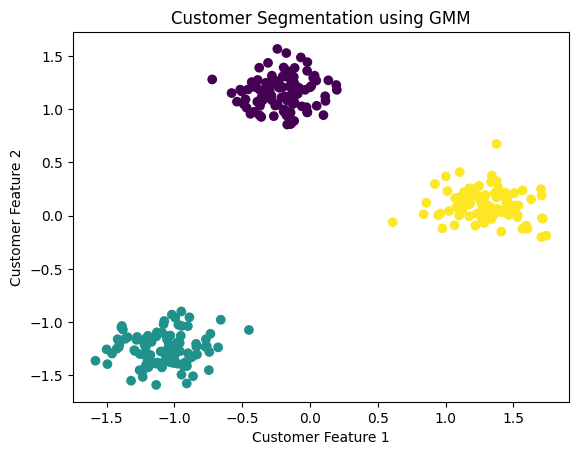


GMM Customer Segmentation Completed


In [15]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler


X, y = make_blobs(
    n_samples=300,
    centers=3,
    n_features=2,
    random_state=42
)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


gmm = GaussianMixture(
    n_components=3,
    random_state=42
)

gmm.fit(X_scaled)


clusters = gmm.predict(X_scaled)

probabilities = gmm.predict_proba(X_scaled)

print("Customer Cluster Labels:")
print(clusters[:10])

print("\nCluster Membership Probabilities:")
print(np.round(probabilities[:10], 3))

print("\nNumber of Customers in Each Cluster:")
for i in range(3):
    print("Cluster", i, ":", np.sum(clusters == i))

print("\nModel Converged:", gmm.converged_)
print("Model AIC:", round(gmm.aic(X_scaled), 2))
print("Model BIC:", round(gmm.bic(X_scaled), 2))


plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap='viridis'
)

plt.xlabel("Customer Feature 1")
plt.ylabel("Customer Feature 2")
plt.title("Customer Segmentation using GMM")
plt.show()

print("\nGMM Customer Segmentation Completed")

Dataset Shape: (569, 30)
Number of Features: 30
Epoch 1/30


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.6401 - loss: 0.6395 - val_accuracy: 0.9011 - val_loss: 0.4944
Epoch 2/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9121 - loss: 0.3546 - val_accuracy: 0.9451 - val_loss: 0.2475
Epoch 3/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9588 - loss: 0.1844 - val_accuracy: 0.9560 - val_loss: 0.1523
Epoch 4/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9643 - loss: 0.1229 - val_accuracy: 0.9670 - val_loss: 0.1110
Epoch 5/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9753 - loss: 0.0979 - val_accuracy: 0.9670 - val_loss: 0.0864
Epoch 6/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9835 - loss: 0.0773 - val_accuracy: 0.9670 - val_loss: 0.0733
Epoch 7/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9835 - loss: 0.0713 - val_accuracy: 0.9780 - val_loss: 0.0665
Epoch 8/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9835 - loss: 0.0626 - val_accuracy: 0.9890 - val_loss: 0.0594
Ep

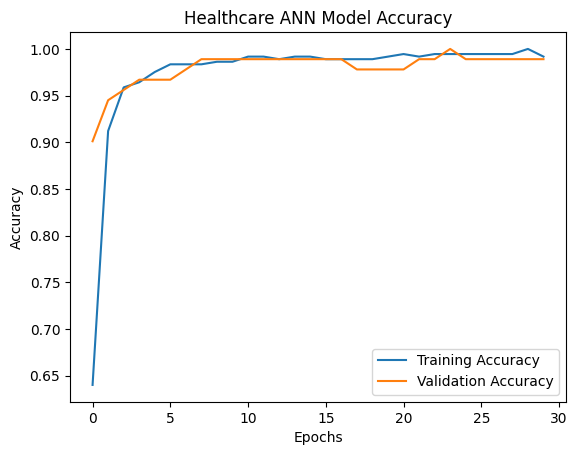

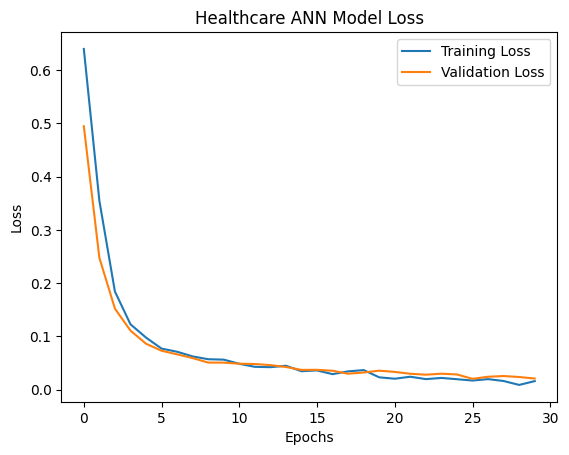


Sample Patient Prediction:
Predicted Class: Malignant
Prediction Probability: 0.0

Healthcare Deep Learning Application Completed


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

data = load_breast_cancer()

X = data.data
y = data.target

print("Dataset Shape:", X.shape)
print("Number of Features:", X.shape[1])


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = Sequential([
    Dense(64, activation='relu',
          input_shape=(X_train.shape[1],)),

    Dropout(0.2),

    Dense(32, activation='relu'),

    Dense(16, activation='relu'),

    Dense(1, activation='sigmoid')
])


model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)


history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

predictions = model.predict(X_test, verbose=0)

y_pred = (predictions > 0.5).astype(int).ravel()

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("\nHealthcare Prediction Results")

print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=data.target_names
))


plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Healthcare ANN Model Accuracy")
plt.legend()
plt.show()


plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Healthcare ANN Model Loss")
plt.legend()
plt.show()


sample = X_test[0].reshape(1, -1)

prediction = model.predict(sample, verbose=0)[0][0]

print("\nSample Patient Prediction:")

if prediction >= 0.5:
    print("Predicted Class: Benign")
else:
    print("Predicted Class: Malignant")

print("Prediction Probability:", round(float(prediction), 4))

print("\nHealthcare Deep Learning Application Completed")